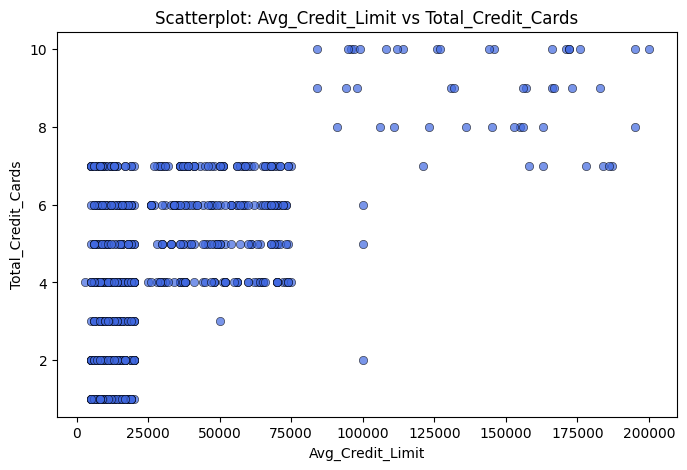

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('CC_Customer_Dataset.csv')

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', alpha=0.7, color='royalblue', edgecolor='k')
plt.title('Scatterplot: Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.show()

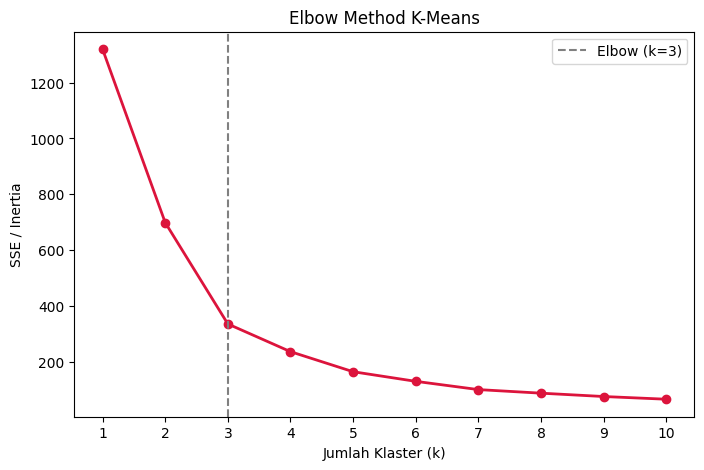

In [17]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Menggunakan 2 variabel sesuai soal nomor 1 (maupun seluruh 5 variabel fitur)
X_2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]
scaler_2 = StandardScaler()
X_2_scaled = scaler_2.fit_transform(X_2)

sse = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_2_scaled)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, sse, marker='o', color='crimson', linewidth=2)
plt.axvline(x=3, color='gray', linestyle='--', label='Elbow (k=3)')
plt.title('Elbow Method K-Means')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('SSE / Inertia')
plt.xticks(K_range)
plt.legend()
plt.show()

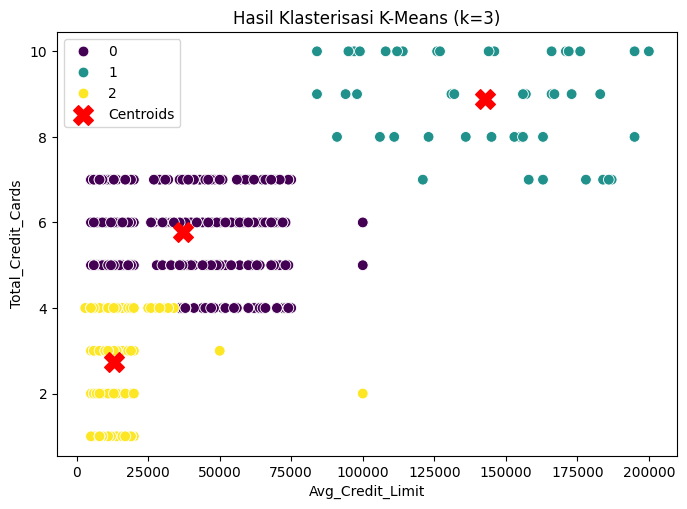

In [18]:
# Pemodelan K-Means dengan k = 3
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans_final.fit_predict(X_2_scaled)

# Mengembalikan koordinat centroid ke skala asli untuk di-plot
centroids = scaler_2.inverse_transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards',
                hue='Cluster_KMeans', palette='viridis', s=60)
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='red', marker='X', label='Centroids')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.legend()
plt.show()

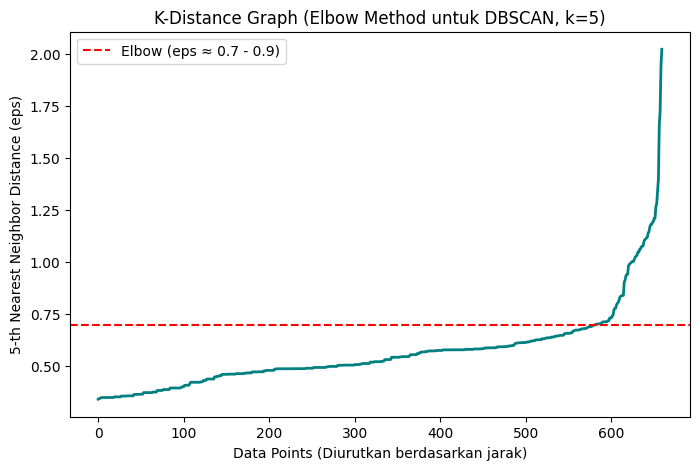

In [19]:
import numpy as np
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

# Mengambil seluruh 5 variabel yang relevan dan melakukan standarisasi
X_all = df.drop(columns=['Sl_No', 'Customer Key', 'Cluster_KMeans'], errors='ignore')
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

# Menentukan jarak tetangga terdekat ke-k (k = 5 sesuai jumlah fitur/min_samples)
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_all_scaled)
distances, indices = neighbors_fit.kneighbors(X_all_scaled)

# Mengurutkan jarak dari terkecil ke terbesar
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(distances, color='teal', linewidth=2)
plt.axhline(y=0.7, color='red', linestyle='--', label='Elbow (eps ≈ 0.7 - 0.9)')
plt.title('K-Distance Graph (Elbow Method untuk DBSCAN, k=5)')
plt.xlabel('Data Points (Diurutkan berdasarkan jarak)')
plt.ylabel('5-th Nearest Neighbor Distance (eps)')
plt.legend()
plt.show()

# Membuat model DBSCAN dengan parameter hasil analisis Elbow
dbscan = DBSCAN(eps=0.9, min_samples=5)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_all_scaled)

In [20]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

labels = dbscan.labels_

# 1. Perhitungan mengikutsertakan titik noise (-1)
sil_score = silhouette_score(X_all_scaled, labels)
dbi_score = davies_bouldin_score(X_all_scaled, labels)

print(f"Silhouette Score (dengan noise): {sil_score:.4f}")
print(f"Davies-Bouldin Index (dengan noise): {dbi_score:.4f}")

# 2. Perhitungan tanpa titik noise (hanya klaster valid != -1)
mask = labels != -1
sil_clean = silhouette_score(X_all_scaled[mask], labels[mask])
dbi_clean = davies_bouldin_score(X_all_scaled[mask], labels[mask])

print(f"Silhouette Score (tanpa noise): {sil_clean:.4f}")
print(f"Davies-Bouldin Index (tanpa noise): {dbi_clean:.4f}")

Silhouette Score (dengan noise): 0.4645
Davies-Bouldin Index (dengan noise): 1.9420
Silhouette Score (tanpa noise): 0.4940
Davies-Bouldin Index (tanpa noise): 0.8784
